In [1]:
%load_ext autoreload
%autoreload 2

import os, sys
dir1 = os.path.dirname(os.path.abspath('..'))
if not dir1 in sys.path: sys.path.append(dir1)

In [2]:
from pathlib import Path
import pickle
import yaml
import numpy as np
import pandas as pd

import seaborn as sns
from utils.plots import *
from utils import models
from utils.figures import plot_metrics
from utils.figures import print_stats
from matplotlib.gridspec import GridSpec
from matplotlib.ticker import StrMethodFormatter

FIG = 'fig4'
config_fpath = Path(f'{FIG}.yml')
df_fpath = Path(f'{FIG}_df.csv')
meta_fpath = Path('../../dfs/aurora_test_ppg_df.csv')

In [3]:
data_dir = Path('../../experiments/aurora_ppg')
idx = '0018'

obs_fpath = data_dir / 'idx' / idx / f'{idx}_sig_obs.csv'
df_obs = pd.read_csv(obs_fpath)
t, y_obs = df_obs.t.values, df_obs.y.values

filt_fpath = data_dir / 'idx' / idx / 'filt' / f'{idx}_F_pyp.csv'
df_filt = pd.read_csv(filt_fpath)
t_pyp, y_pyp = df_filt.t.values, df_filt.y.values

time_fpath = data_dir / 'idx' / idx / 'time' / f'{idx}_F_pyp_T_pyp.u.csv'
df_time = pd.read_csv(time_fpath)
z_pyp = df_time.z.values
zp_pyp = np.diff(z_pyp)
loc_pyp = np.array([np.argmin(np.abs(t-z)) for z in z_pyp])

bpd_fpath = data_dir / 'idx' / idx / 'filt' / f'{idx}_F_bpd.csv'
df_bpd = pd.read_csv(bpd_fpath)
t_bpd, y_bpd = df_bpd.t.values, df_bpd.y.values

sol_fpath = data_dir / 'idx' / idx / f'{idx}_soln_bpd.pkl'
with open(sol_fpath, 'rb') as f:
    bpd = pickle.load(f)
z_bpd = bpd['z']
zp_bpd = np.diff(z_bpd)

assert np.all(np.isclose(t, t_pyp))
assert np.all(np.isclose(t, t_bpd))
fs = (t.size-1)/(t.max() - t.min())

true_fpath = data_dir / 'idx' / idx / f'{idx}_soln_true.pkl'
with open(true_fpath, 'rb') as f:
    true = pickle.load(f)
z_true = true['z']
zp_true = np.diff(z_true)

aurora_df_dir = Path('../../dfs/aurora_test_ppg_df.csv')
df_aurora = pd.read_csv(aurora_df_dir)
row = df_aurora.iloc[int(idx)]
print(row[['age', 'posture']])
ecg_fpath = Path('../../../data/aurora') / row.waveform_file_path
df_wav = pd.read_csv(ecg_fpath, delimiter='\t')
t_ecg = df_wav['t'].values
ecg = df_wav['ekg'].values


age          48.0
posture    supine
Name: 18, dtype: object


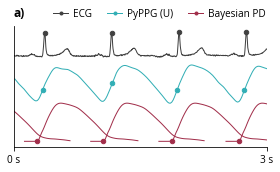

In [4]:
PAT_OFFSET = 0.3

ecg_color = '#404040'

def subfigure_a(sub='a)'):
    ta, tb = 6, 9
    size = 20

    win_ecg = (t_ecg >= ta) & (t_ecg <= tb)
    tt, yy = t_ecg[win_ecg].copy(), ecg[win_ecg].copy()
    tt += PAT_OFFSET
    yy *= -1
    yy -= yy.min()
    yy /= yy.max() * 1.5
    loc_true = np.array([np.argmin(np.abs(tt-z)) for z in z_true if (ta<=z-PAT_OFFSET<=tb)])
    plt.plot(tt, yy, c=ecg_color, alpha=1, zorder=-1)
    plt.scatter(tt[loc_true], yy[loc_true], c=ecg_color, s=size)

    win = (t >= ta+PAT_OFFSET) & (t <= tb+PAT_OFFSET)
    tt, yy = t[win].copy(), y_pyp[win].copy()
    yy -= yy.min()
    yy /= yy.max()
    yy -= 1.2
    loc_pyp = np.array([np.argmin(np.abs(tt-z)) for z in z_pyp if (ta<=z-PAT_OFFSET<=tb)])
    plt.plot(tt, yy, c=cp[3])
    plt.scatter(tt[loc_pyp], yy[loc_pyp], c=cp[3], s=size)

    win = (t >= ta+PAT_OFFSET) & (t <= tb+PAT_OFFSET)
    tt, yy = t[win].copy(), y_bpd[win].copy()
    yy -= yy.min()
    yy /= yy.max()
    yy -= 2
    hh = models.h_fun(tt-tt[0], bpd['w'], bpd['f_h'], bpd['g'])
    scale = hh.max()
    for z in z_bpd:
        if not (ta-1<=z-PAT_OFFSET<=tb):
            continue

        t_h = np.arange(-0.15, 1.2, 1/fs)
        hh = models.h_fun(t_h*0.9, bpd['w'], bpd['f_h'], bpd['g'])/scale - 2.2
        plt.plot(t_h+z, hh, c=cp[1])
        plt.scatter([z], [hh[np.argmax(t_h >= 0)]], c=cp[1], s=size)

    plt.xlim(ta+PAT_OFFSET, tb+PAT_OFFSET)
    plt.yticks([])
    plt.xticks([ta+PAT_OFFSET, tb+PAT_OFFSET], ['0 s', f'{tb-ta:0g} s'])
    sns.despine(ax=plt.gca())

    plt.plot([np.nan], [np.nan], '.-', c=ecg_color, label='ECG')
    plt.plot([np.nan], [np.nan], '.-', c=cp[3], label='PyPPG (U)')
    plt.plot([np.nan], [np.nan], '.-', c=cp[1], label='Bayesian PD')
    plt.legend(loc='lower right', bbox_to_anchor=(1, 1.05),
               ncol=3, columnspacing=1.5,
               frameon=False, borderpad=0.0, borderaxespad=0.1,
               handlelength=1.5, handletextpad=0.5)

    plt.title(sub, loc='left', pad=10, fontdict={'fontweight': 'bold'})

    
plt.figure(figsize=(4,2.5))
df_temp = subfigure_a()
plt.show()


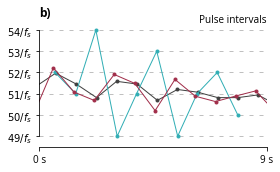

In [5]:
def subfigure_b(sub='b)'):
    ta, tb = t[0], t[-1]
    ta, tb = t[0], t[0] + 9
    
    plt.plot(z_true[:-1], zp_true*fs, '.-', c=ecg_color)
    plt.plot(z_pyp[:-1], zp_pyp*fs, '.-', c=cp[3])
    plt.plot(z_bpd[:-1], zp_bpd*fs, '.-', c=cp[1])

    for i in range(49, 55):
        plt.hlines([i], ta, tb, color=cp[-1], zorder=-1, ls=(0, (4, 6)))

    yticks = [49, 50, 51, 52, 53, 54]
    plt.gca().yaxis.set_major_formatter(StrMethodFormatter(r"${x:0g}/f_s$"))
    plt.yticks(yticks)

    plt.xticks([ta, tb], ['0 s', f'{tb-ta:0g} s'])
    plt.xlim(ta, tb)
    plt.gca().set_ymargin(0.1)
    sns.despine(ax=plt.gca(), trim=True)

    plt.plot([np.nan], [np.nan], lw=0, label='Pulse intervals')
    plt.legend(loc='center right', bbox_to_anchor=(1, 1),
               ncol=3, columnspacing=1.5,
               frameon=False, borderpad=0.0, borderaxespad=0.1,
               handlelength=1.5, handletextpad=0.5)
    
    plt.title(sub, loc='left', pad=0, fontdict={'fontweight': 'bold'})

plt.figure(figsize=(4,2.5))
df_temp = subfigure_b()
plt.show()


In [6]:
with open(config_fpath, 'r') as f:
    config = yaml.safe_load(f)
df = pd.read_csv(df_fpath)

median metrics:
method
F_pyp_T_pyp.u    0.008314
T_bpd            0.005085
Name: zp_rmse, dtype: float64

***	p=1.098E-10, PyPPG (U) <> Bayesian PD



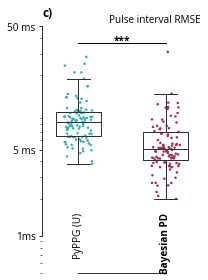

In [14]:
def subfigure_c(sub='c)', debug=False, stats=False):
    y = config['y'][0]
    metric = y['metric']

    title = y['name']
    methods = [x['method'] for x in y['x']]
    names = [x['name'] for x in y['x']]
    df_temp = plot_metrics(df, metric, methods, names, log=True, markersize=2.5,
                           boxwidth=0.65)
    
    plt.gca().set_xmargin(0.1)
    
    plt.gca().tick_params(axis="x", direction="in", pad=-61)
    if not debug:
        plt.minorticks_off()
    plt.yticks([0.001, 0.005, 0.05, 0.5, 5], ['1ms', '5 ms', '50 ms', '500 ms', '5s'])
    plt.ylim(0.0005, 0.05)
    sns.despine(ax=plt.gca(), bottom=(not debug), trim=True)
    labels = plt.gca().get_xticklabels()
    labels[-1].set_weight('bold')

    plt.plot([np.nan], [np.nan], lw=0, label=title)
    plt.legend(loc='lower right', bbox_to_anchor=(1, 1),
               ncol=3, columnspacing=1.5,
               frameon=False, borderpad=0.0, borderaxespad=0.1,
               handlelength=1.5, handletextpad=0.5)
    plt.title(sub, loc='left', pad=10, fontdict={'fontweight': 'bold'})

    star_y = 0.037
    plt.plot([0, 1], [star_y, star_y], c='k', lw=1)
    plt.text(0.5, star_y, '***', ha='center', fontdict={'fontweight':'bold'},)

    if stats:
        print_stats(df_temp, metric, methods, names)

    return df_temp

plt.figure(figsize=(3,4))
df_temp = subfigure_c(debug=True, stats=True)
plt.show()


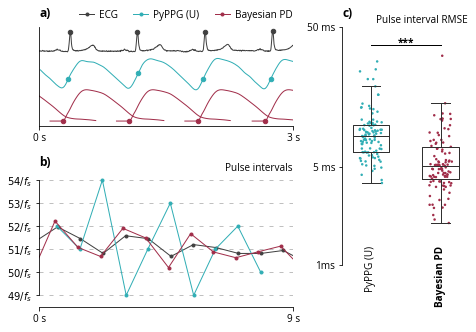

In [16]:
fig = plt.figure(figsize=(6.5,4.5), layout="constrained")

titlefont = {'fontweight':'bold'}
gs = GridSpec(2, 2, figure=fig,
              width_ratios=[2., 1], height_ratios=[1, 1.4],
              wspace=0.03, hspace=0.0)
fig.add_subplot(gs[0, 0])
subfigure_a()
fig.add_subplot(gs[1, 0])
subfigure_b()
fig.add_subplot(gs[:, 1])
subfigure_c('c)')

plt.savefig(f'{FIG}.pdf', transparent=True)
plt.savefig(f'{FIG}.png', transparent=True, dpi=200)
plt.show()
